# Visualização com Matplotlib e Seaborn

Gráficos estáticos e estatísticos com foco em clareza, acessibilidade e interpretação.

Os exemplos usam arquivos pequenos da pasta `datasets/` e podem ser executados na ordem. Exercícios resolvidos aparecem junto dos respectivos enunciados.

**Objetivo:** selecionar a visualização pela pergunta, rotular unidades corretamente e mostrar limitações de medidas incompletas e pequenas amostras.

### Materiais complementares

- [Guia — Matplotlib e Seaborn](./reference_materials/05_visualizacao_com_matplotlib_e_seaborn.pdf)
- [Cheat sheet — Matplotlib](./cheat_sheets/cheat_sheet_matplotlib.pdf)
- [Cheat sheet — Seaborn](./cheat_sheets/cheat_sheet_seaborn.pdf)

Os arquivos estão nesta mesma pasta da disciplina. Os PDFs complementam, mas não substituem, a execução das células.

## 1. Matplotlib — figura, eixos e rótulos

Gráficos devem responder a perguntas. Escolha eixos, unidades e escala adequados e evite efeitos visuais que dificultem comparações.

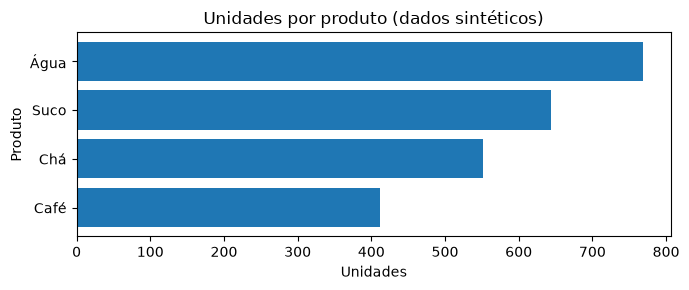

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

def preparar_pastas():
    """Localiza a biblioteca e cria as pastas de dados e resultados, se ausentes."""
    atual = Path.cwd().resolve()
    # Aceita execução na raiz da biblioteca ou em uma pasta filha.
    candidatos = [atual, atual.parent]
    raiz = next(
        (p for p in candidatos if (p / 'vendas_exemplo.csv').is_file() or
         (p / 'datasets' / 'vendas_exemplo.csv').is_file()),
        None,
    )
    if raiz is None:
        # Identifica a raiz da biblioteca pelo conjunto de notebooks.
        raiz = next(
            (p for p in candidatos if (p / '01_Analise_Exploratoria_de_Dados.ipynb').is_file()),
            atual,
        )
    dados = raiz / 'datasets'
    saidas = raiz / 'outputs'
    dados.mkdir(parents=True, exist_ok=True)
    saidas.mkdir(parents=True, exist_ok=True)
    return dados, saidas

DATA, OUTPUTS = preparar_pastas()

def conferir_datasets(*nomes):
    ausentes = [nome for nome in nomes if not (DATA / nome).is_file()]
    if ausentes:
        raise FileNotFoundError(
            'Datasets ausentes: ' + ', '.join(ausentes) + '\n'
            + 'Coloque os CSVs fornecidos em: ' + str(DATA.resolve()) + '\n'
            + 'Criar a pasta datasets/ não cria automaticamente os arquivos CSV.'
        )
conferir_datasets('vendas_exemplo.csv', 'clima_sintetico.csv')
import matplotlib.pyplot as plt
vendas=pd.read_csv(DATA/'vendas_exemplo.csv').drop_duplicates()
totais=vendas.groupby('produto')['unidades'].sum().sort_values()
fig,ax=plt.subplots(figsize=(7,3))
ax.barh(totais.index,totais.values)
ax.set(title='Unidades por produto (dados sintéticos)',xlabel='Unidades',ylabel='Produto')
plt.tight_layout();plt.show()

## 2. Seaborn — distribuições e categorias

Seaborn fornece uma interface estatística sobre Matplotlib. Um boxplot mostra mediana, quartis e possíveis extremos, mas não substitui a inspeção do tamanho dos grupos.

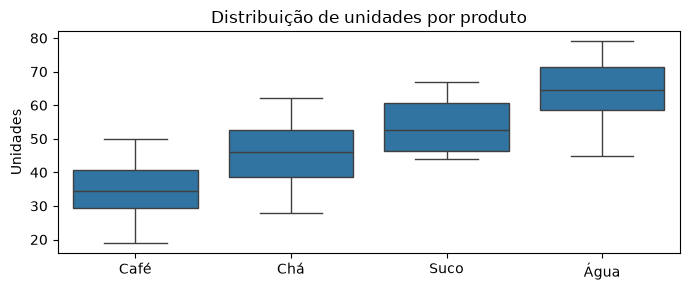

In [2]:
import seaborn as sns
fig,ax=plt.subplots(figsize=(7,3))
sns.boxplot(data=vendas,x='produto',y='unidades',ax=ax)
ax.set(title='Distribuição de unidades por produto',xlabel='',ylabel='Unidades')
plt.tight_layout();plt.show()

## 3. Dispersão, associação e leitura cautelosa

Uma tendência visual não prova causalidade. Quando a cor representa categorias, mantenha uma legenda legível.

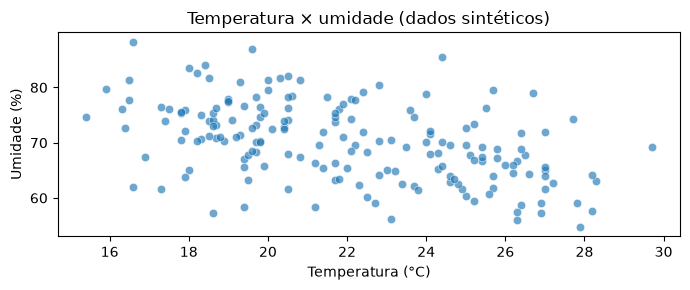

In [3]:
clima=pd.read_csv(DATA/'clima_sintetico.csv')
fig,ax=plt.subplots(figsize=(7,3))
sns.scatterplot(data=clima,x='temperatura_c',y='umidade_pct',ax=ax,alpha=.65)
ax.set(title='Temperatura × umidade (dados sintéticos)',xlabel='Temperatura (°C)',ylabel='Umidade (%)')
plt.tight_layout();plt.show()

## 4. Subplots e comparação de escalas

Em painéis, identifique claramente unidades e títulos. Evite comparar visualmente grandezas de escalas diferentes como se fossem equivalentes.

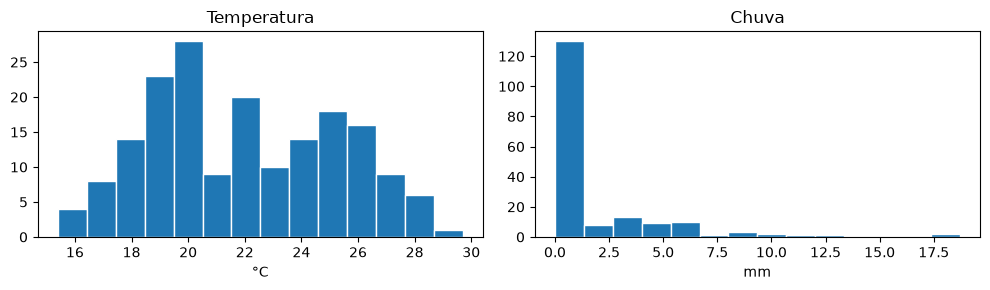

In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].hist(clima['temperatura_c'],bins=14,edgecolor='white')
axes[1].hist(clima['chuva_mm'],bins=14,edgecolor='white')
axes[0].set(title='Temperatura',xlabel='°C');axes[1].set(title='Chuva',xlabel='mm')
plt.tight_layout();plt.show()

## 5. Exercício resolvido — reduzir poluição visual

**Enunciado:** represente a evolução mensal de temperatura com uma linha, unidades, marcadores discretos e grade suave.

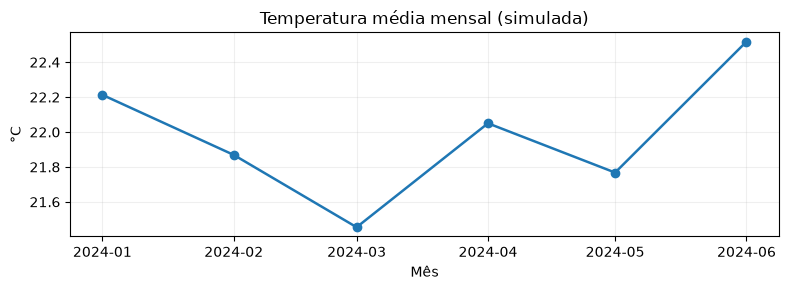

In [5]:
clima['data']=pd.to_datetime(clima['data'])
medias=clima.set_index('data')['temperatura_c'].resample('MS').mean()
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(medias.index,medias.values,marker='o',linewidth=1.8)
ax.grid(alpha=.2)
ax.set(title='Temperatura média mensal (simulada)',ylabel='°C',xlabel='Mês')
plt.tight_layout();plt.show()

## 6. Personalização de eixos, legendas e exportação
Uma visualização legível informa unidades, período, eixo e fonte. Para datas, use formatadores próprios. Exporte figuras em `outputs/` sem misturá-las com os dados de entrada.

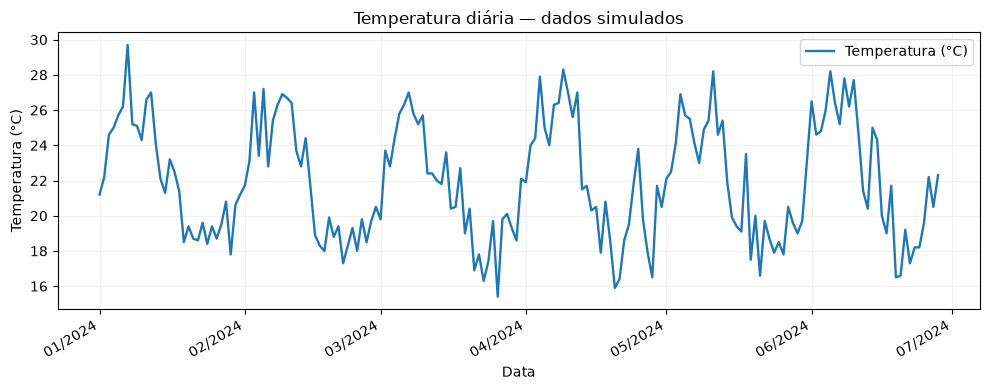

Figura exportada para outputs/temperatura_diaria.png


In [6]:
import matplotlib.dates as mdates
from pathlib import Path
clima['data'] = pd.to_datetime(clima['data'])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(clima['data'], clima['temperatura_c'], label='Temperatura (°C)', linewidth=1.7)
ax.set(title='Temperatura diária — dados simulados', xlabel='Data', ylabel='Temperatura (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax.grid(alpha=.18)
ax.legend(loc='best')
fig.autofmt_xdate(); fig.tight_layout()
# OUTPUTS foi preparado na primeira célula
fig.savefig(OUTPUTS/'temperatura_diaria.png', dpi=140, bbox_inches='tight')
plt.show()
print('Figura exportada para outputs/temperatura_diaria.png')

## 7. Heatmap, distribuições condicionais e cores
Heatmaps sintetizam uma matriz; violinos, boxplots e histogramas mostram a distribuição. Escolha uma paleta perceptualmente legível e não dependa apenas da cor para distinguir informações.

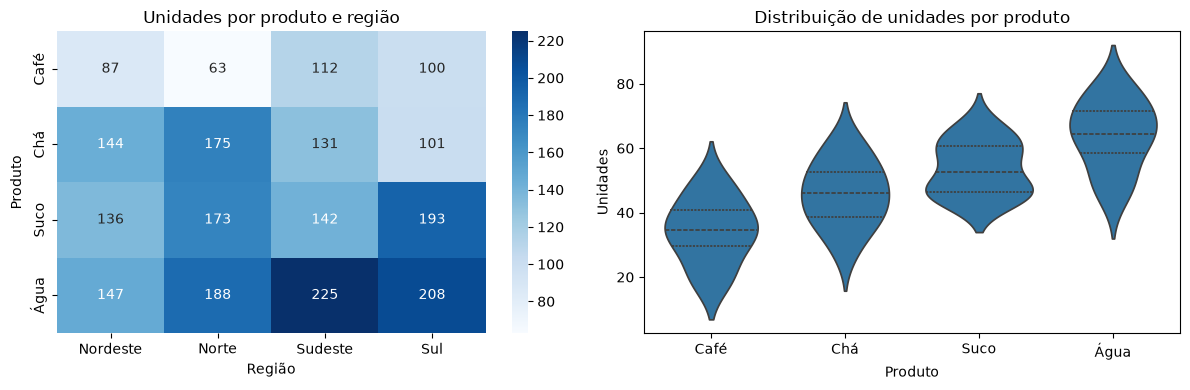

In [7]:
matriz = vendas.pivot_table(index='produto', columns='regiao', values='unidades', aggfunc='sum', fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(matriz, annot=True, fmt='.0f', cmap='Blues', ax=axes[0])
axes[0].set(title='Unidades por produto e região', xlabel='Região', ylabel='Produto')
sns.violinplot(data=vendas, x='produto', y='unidades', ax=axes[1], inner='quartile')
axes[1].set(title='Distribuição de unidades por produto', xlabel='Produto', ylabel='Unidades')
fig.tight_layout(); plt.show()

## 8. Barras de erro e comunicação de incerteza
Barras de erro podem representar amplitude, desvio ou intervalo de confiança — isso deve ser indicado. Aqui usamos **desvio-padrão da amostra**, não intervalo de confiança.

**Interpretação:** desvio-padrão descreve variabilidade entre registros; não é automaticamente intervalo de confiança ou erro de medição. A interpretação exige tamanho da amostra e unidade observacional.

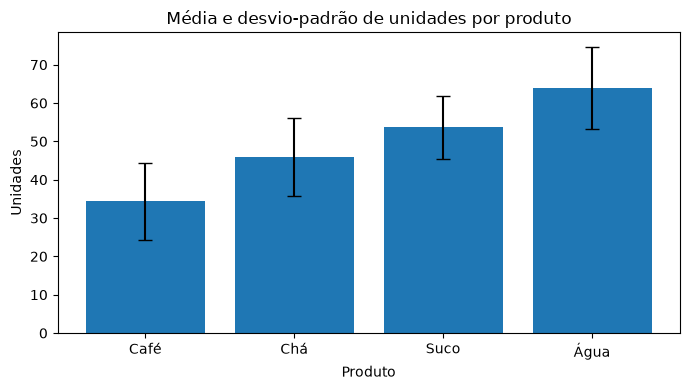

          mean    std  count
produto                     
Café     34.33   9.98     12
Chá      45.92  10.07     12
Suco     53.67   8.26     12
Água     64.00  10.71     12


In [8]:
resumo_produto = vendas.groupby('produto')['unidades'].agg(['mean', 'std', 'count']).sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(resumo_produto.index, resumo_produto['mean'], yerr=resumo_produto['std'], capsize=5)
ax.set(title='Média e desvio-padrão de unidades por produto', ylabel='Unidades', xlabel='Produto')
fig.tight_layout(); plt.show()
print(resumo_produto.round(2))

## 9. Facetas e comparações entre grupos
Facetas exibem o mesmo gráfico dividido por grupo, evitando múltiplas séries sobrepostas. Mantenha escalas comparáveis quando a pergunta for comparação de magnitudes.

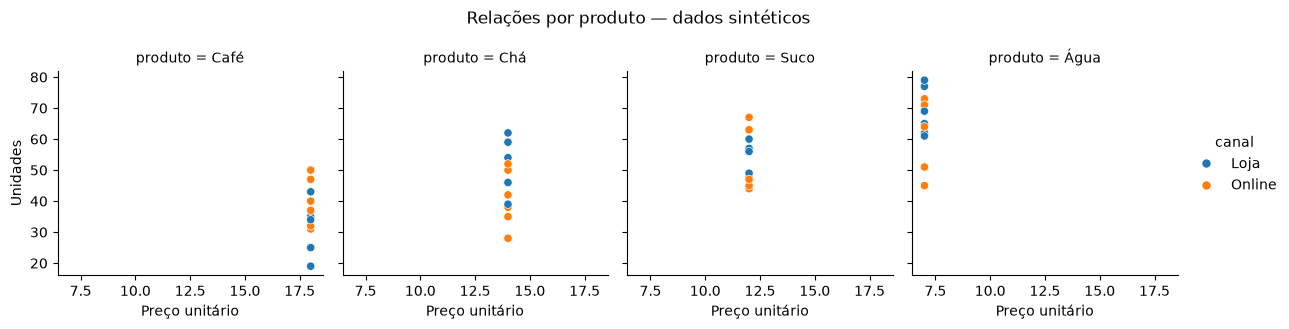

In [9]:
grades = sns.relplot(data=vendas, x='preco_unitario', y='unidades', col='produto', hue='canal', kind='scatter', height=3, facet_kws={'sharex':True,'sharey':True})
grades.set_axis_labels('Preço unitário', 'Unidades')
grades.fig.suptitle('Relações por produto — dados sintéticos', y=1.08)
plt.show()

## 10. Exercício resolvido — corrigir um gráfico enganoso
**Enunciado:** compare regiões por receita usando eixo iniciado em zero, valores anotados, unidade explícita e categorias ordenadas. **Interpretação:** as barras mostram o montante nos dados simulados, não qualidade de atendimento ou crescimento.

**Limitação:** as barras representam somas da receita **conhecida**. Se existirem preços ausentes, não sabemos o total verdadeiro; o gráfico não deve ser apresentado como receita completa.

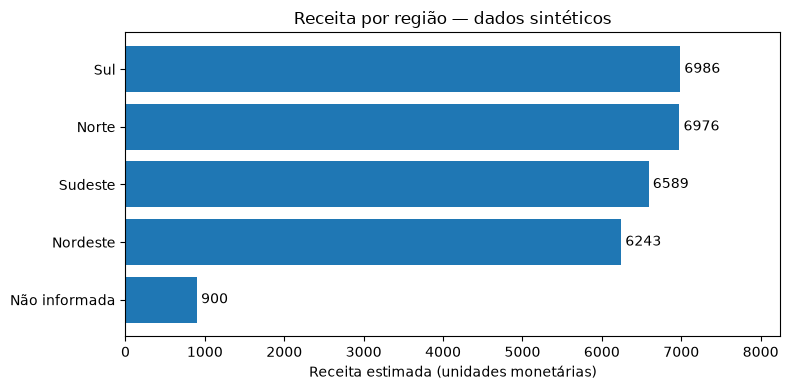

In [10]:
vendas_vis = vendas.copy()
vendas_vis['receita'] = vendas_vis['unidades'] * vendas_vis['preco_unitario']
serie = vendas_vis.groupby('regiao', dropna=False)['receita'].sum(min_count=1).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.barh(serie.index.fillna('Não informada'), serie.values)
ax.bar_label(barras, fmt='%.0f', padding=3)
ax.set(xlabel='Receita estimada (unidades monetárias)', title='Receita por região — dados sintéticos')
ax.set_xlim(left=0, right=max(serie.max()*1.18, 1))
fig.tight_layout(); plt.show()

### Consulta rápida — visualização
| Objetivo | Sugestão |
|---|---|
| Comparar categorias | Barras ordenadas e eixo em zero |
| Mostrar distribuição | Histograma e boxplot |
| Mostrar relação | Dispersão, com observação sobre causalidade |
| Mostrar variação temporal | Linhas, com datas e unidades |
| Comparar duas dimensões | Heatmap ou facetas |
| Exportar | `fig.savefig(Path('outputs') / 'grafico.png', dpi=140)` |

## 11. Exercício resolvido — escolher o gráfico e verificar a cobertura

**Enunciado:** apresente as unidades por produto em barras horizontais ordenadas e compare a cobertura de preços por produto. Barras servem para comparar categorias; cobertura ajuda a interpretar valores financeiros incompletos.

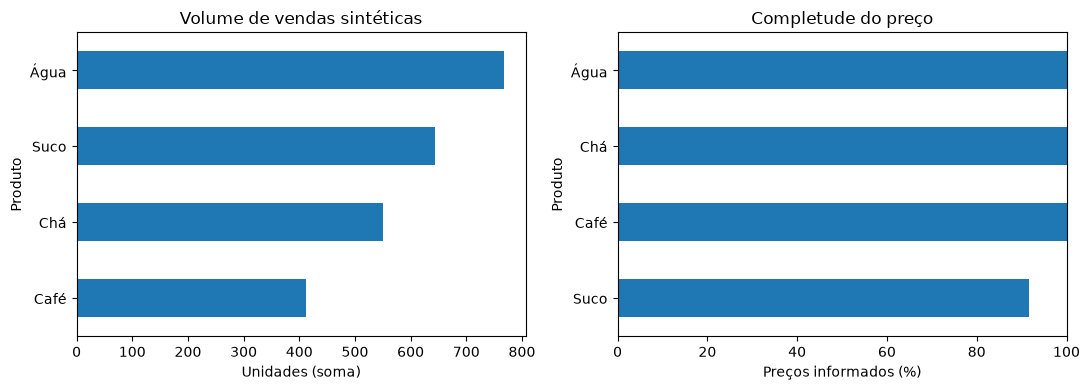

         registros  precos_validos  unidades  cobertura_pct
produto                                                    
Café            12              12       412          100.0
Chá             12              12       551          100.0
Suco            12              11       644           91.7
Água            12              12       768          100.0


In [11]:
cobertura_preco = vendas.groupby('produto').agg(
    registros=('produto', 'size'), precos_validos=('preco_unitario', 'count'),
    unidades=('unidades', 'sum')
)
cobertura_preco['cobertura_pct'] = 100*cobertura_preco['precos_validos']/cobertura_preco['registros']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cobertura_preco['unidades'].sort_values().plot.barh(ax=axes[0])
axes[0].set(xlabel='Unidades (soma)', ylabel='Produto', title='Volume de vendas sintéticas')
cobertura_preco['cobertura_pct'].sort_values().plot.barh(ax=axes[1])
axes[1].set(xlabel='Preços informados (%)', ylabel='Produto', title='Completude do preço', xlim=(0, 100))
fig.tight_layout();plt.show()
assert cobertura_preco['cobertura_pct'].between(0, 100).all()
print(cobertura_preco.round(1).to_string())

### Qual gráfico usar?

| Pergunta | Gráfico apropriado | Cuidado |
|---|---|---|
| Comparar categorias | Barras ordenadas | Eixo de valores começa em zero |
| Distribuição numérica | Histograma/boxplot | Mostre número de observações |
| Relação numérica | Dispersão | Associação não implica causalidade |
| Evolução temporal | Linha | Ordene datas e evite períodos enganosos |
| Comparar grupos e distribuição | Facetas/boxplot | Esclareça diferenças de escalas |

A paleta não deve ser a única forma de codificar diferenças e títulos precisam indicar unidade e período.

## Consulta rápida de boas práticas

- Informe unidades, período e fonte.
- Use cores com contraste suficiente e não dependa apenas da cor.
- Não corte eixos de barras de modo a exagerar diferenças.
- Evite excesso de categorias ou rótulos ilegíveis.
- Diferencie associação, comparação e evolução temporal.
- Para dados reais, inclua limitações e incertezas relevantes.

## Aprofundamento v2 — gráficos honestos e acessíveis

Escolha o tipo de marca visual conforme a pergunta: barras para comparar magnitudes (preferencialmente com eixo zero), linhas para trajetórias temporais e dispersão para relações. Evite depender somente de cores para identificar categorias; use rótulos, formas ou legendas. Eixos truncados podem exagerar diferenças.

**Exercício resolvido:** construir um gráfico de barras com rótulos explícitos e origem zero.

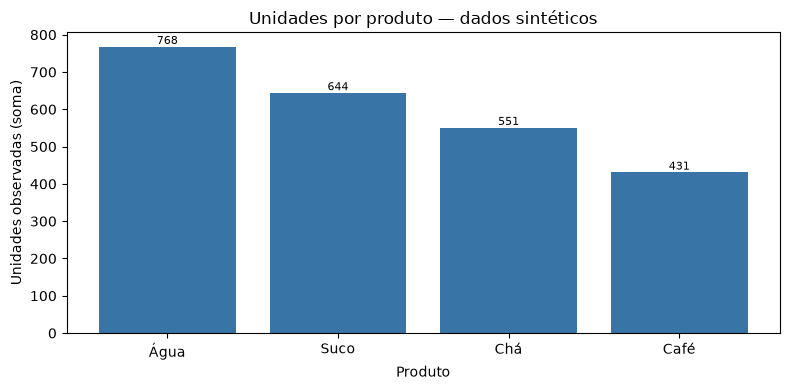

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
v2_resumo = (pd.read_csv(DATA / 'vendas_exemplo.csv')
             .groupby('produto',dropna=False)['unidades'].sum().sort_values(ascending=False))
fig_v2, ax_v2 = plt.subplots(figsize=(8,4))
ax_v2.bar(v2_resumo.index.astype(str),v2_resumo.values,color='#3974a6')
ax_v2.set_ylim(bottom=0)
ax_v2.set_ylabel('Unidades observadas (soma)')
ax_v2.set_xlabel('Produto')
ax_v2.set_title('Unidades por produto — dados sintéticos')
for indice, quantidade in enumerate(v2_resumo.values):
    ax_v2.annotate(f'{quantidade:g}',(indice,quantidade),ha='center',va='bottom',fontsize=8)
fig_v2.tight_layout()
plt.show()
assert ax_v2.get_ylim()[0] == 0

**Interpretação:** quantidades agregadas não implicam lucro, participação de mercado nem efeito causal. Reporte fonte sintética, período e denominador quando houver proporções.